# HW04：降维、PCA 与 UMAP

姓名：宗笑语  
学号：22920212204339  
完成日期：2026-11-03

本分析严格使用课程提供的 72 份白血病样本和 7,129 个探针特征。描述性 PCA/UMAP 在全部 72 行上拟合，诊断只在拟合后用于着色；预测对照只使用原始 38 个训练样本。

## 任务 1：降维是为了看图，还是预测新样本？

| 目标 | 需要什么输出 | 如何判断有用 |
|---|---|---|
| 可视化 | 2D/3D 坐标和着色散点图 | 相似样本是否靠近、模式在参数变化下是否稳定、是否便于追踪样本 |
| 去噪 | 去掉低价值方向后的重建或下游表现 | 验证集表现是否改善，重建误差与信号保留是否合理 |
| 压缩特征 | 更少的主成分或嵌入维度 | 在可接受的信息损失下显著减少维度、计算和存储 |
| 发现样本结构 | 邻域、连续梯度、离群点或候选簇 | 多种设置/数据划分下能否复现，并排除批次等混杂 |
| 作为后续模型输入 | 训练折内拟合的降维器及验证分数 | 用严格交叉验证或独立测试评估新样本泛化，不看训练分数下结论 |

**描述当前 72 个样本：**表达矩阵 → 在 72 行上拟合标准化 → 在 72 行上拟合 PCA/UMAP → 拟合结束后按诊断着色。输出只描述当前样本。

**评估新样本预测：**先划分训练/验证折 → 只在训练折拟合标准化、PCA 和分类器 → 用同一套变换处理验证折 → 预测并计算 balanced accuracy → 固定方案后才评估独立测试集。

PCA 虽然不读取诊断标签，但如果先在全数据上拟合，它的均值、标准差和主成分方向已经利用了验证折特征分布。验证数据因此参与了特征表示的选择，交叉验证不再模拟真正未见过的新样本，这仍是信息泄露。

In [1]:
from pathlib import Path
from collections import OrderedDict
import hashlib
import importlib.metadata
import platform
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from scipy.spatial import procrustes
from scipy.spatial.distance import pdist
from scipy.stats import spearmanr
import sklearn
from sklearn.decomposition import PCA
from sklearn.manifold import trustworthiness
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import umap

warnings.filterwarnings("ignore", category=FutureWarning)
plt.style.use("seaborn-v0_8-whitegrid")

HERE = Path.cwd().resolve()
REPO = next(
    (p for p in [HERE, *HERE.parents]
     if (p / "assignments/hw04/resources/data/leukemia/leukemia.csv").exists()),
    None,
)
if REPO is None:
    raise RuntimeError("请在课程仓库内运行本 Notebook")

DATA = REPO / "assignments/hw04/resources/data/leukemia/leukemia.csv"
OUT = REPO / ".tmp/dimension-reduction/student-results"
OUT.mkdir(parents=True, exist_ok=True)

versions = {
    "Python": platform.python_version(),
    "NumPy": np.__version__,
    "pandas": pd.__version__,
    "SciPy": scipy.__version__,
    "scikit-learn": sklearn.__version__,
    "umap-learn": importlib.metadata.version("umap-learn"),
    "matplotlib": importlib.metadata.version("matplotlib"),
}
print(versions)
print("数据路径:", DATA.relative_to(REPO))
print("可重新生成的结果目录:", OUT.relative_to(REPO))

{'Python': '3.14.0', 'NumPy': '2.4.4', 'pandas': '3.0.2', 'SciPy': '1.17.1', 'scikit-learn': '1.8.0', 'umap-learn': '0.5.12', 'matplotlib': '3.10.8'}
数据路径: assignments\hw04\resources\data\leukemia\leukemia.csv
可重新生成的结果目录: .tmp\dimension-reduction\student-results


## 数据检查

每行是一份白血病样本的微阵列表达谱；模型输入是除 `sample_id`、`original_split`、`diagnosis` 外的 7,129 个探针。探针不等于不同基因，且数据含负值，所以本作业不直接取对数。

In [2]:
df = pd.read_csv(DATA)
metadata_cols = ["sample_id", "original_split", "diagnosis"]
feature_names = df.columns.drop(metadata_cols).to_numpy()
X = df.loc[:, feature_names].to_numpy(dtype=float)
y = df["diagnosis"].to_numpy()

sha256 = hashlib.sha256(DATA.read_bytes()).hexdigest()
assert X.shape == (72, 7129)
assert sha256 == "915bce00295ac470f6bd970a4032730a170a080642a5da53ab0bcb0545156f19"

print("矩阵形状 n, p:", X.shape)
print("p/n:", round(X.shape[1] / X.shape[0], 6))
print("类别计数:", df["diagnosis"].value_counts().to_dict())
print("原始划分与类别:\n", df.groupby(["original_split", "diagnosis"]).size().to_string())
print("有限值:", bool(np.isfinite(X).all()))
print("最小值、最大值:", float(X.min()), float(X.max()))
print("负值数、零值数:", int((X < 0).sum()), int((X == 0).sum()))
print("CSV SHA-256:", sha256)

矩阵形状 n, p: (72, 7129)
p/n: 99.013889
类别计数: {'ALL': 47, 'AML': 25}
原始划分与类别:
 original_split  diagnosis
test            ALL          20
                AML          14
train           ALL          27
                AML          11
有限值: True
最小值、最大值: -28400.0 71369.0
负值数、零值数: 147174 1615
CSV SHA-256: 915bce00295ac470f6bd970a4032730a170a080642a5da53ab0bcb0545156f19


## 任务 2：PCA 保留了什么，又丢掉了什么？

先按探针做 z-score，使每列均值约为 0、总体标准差约为 1，再在全部 72 行上做描述性 PCA。这里把 `components_.T` 称为主成分方向权重（loading）。样本的 PC1 得分等于该样本所有标准化探针值分别乘以 PC1 权重后求和。

标准化后最大绝对列均值: 5.983e-16
标准化后总体列标准差范围(ddof=0): 1.000000 到 1.000000
PC1解释率: 0.149216 (14.922%)
PC2解释率: 0.094462 (9.446%)
PC1+PC2累计解释率: 0.243678 (24.368%)
前10个主成分累计解释率: [0.149216, 0.243678, 0.29038, 0.330734, 0.365014, 0.396898, 0.423968, 0.448167, 0.470274, 0.491773]
PC1绝对权重最大的5个探针:
       probe  PC1_loading  abs_loading
X92518_s_at     0.028786     0.028786
  X95190_at    -0.028177     0.028177
  X98253_at     0.027927     0.027927
  X82895_at     0.027871     0.027871
  Y09616_at     0.027757     0.027757
数值上大于1e-12的主成分个数: 71


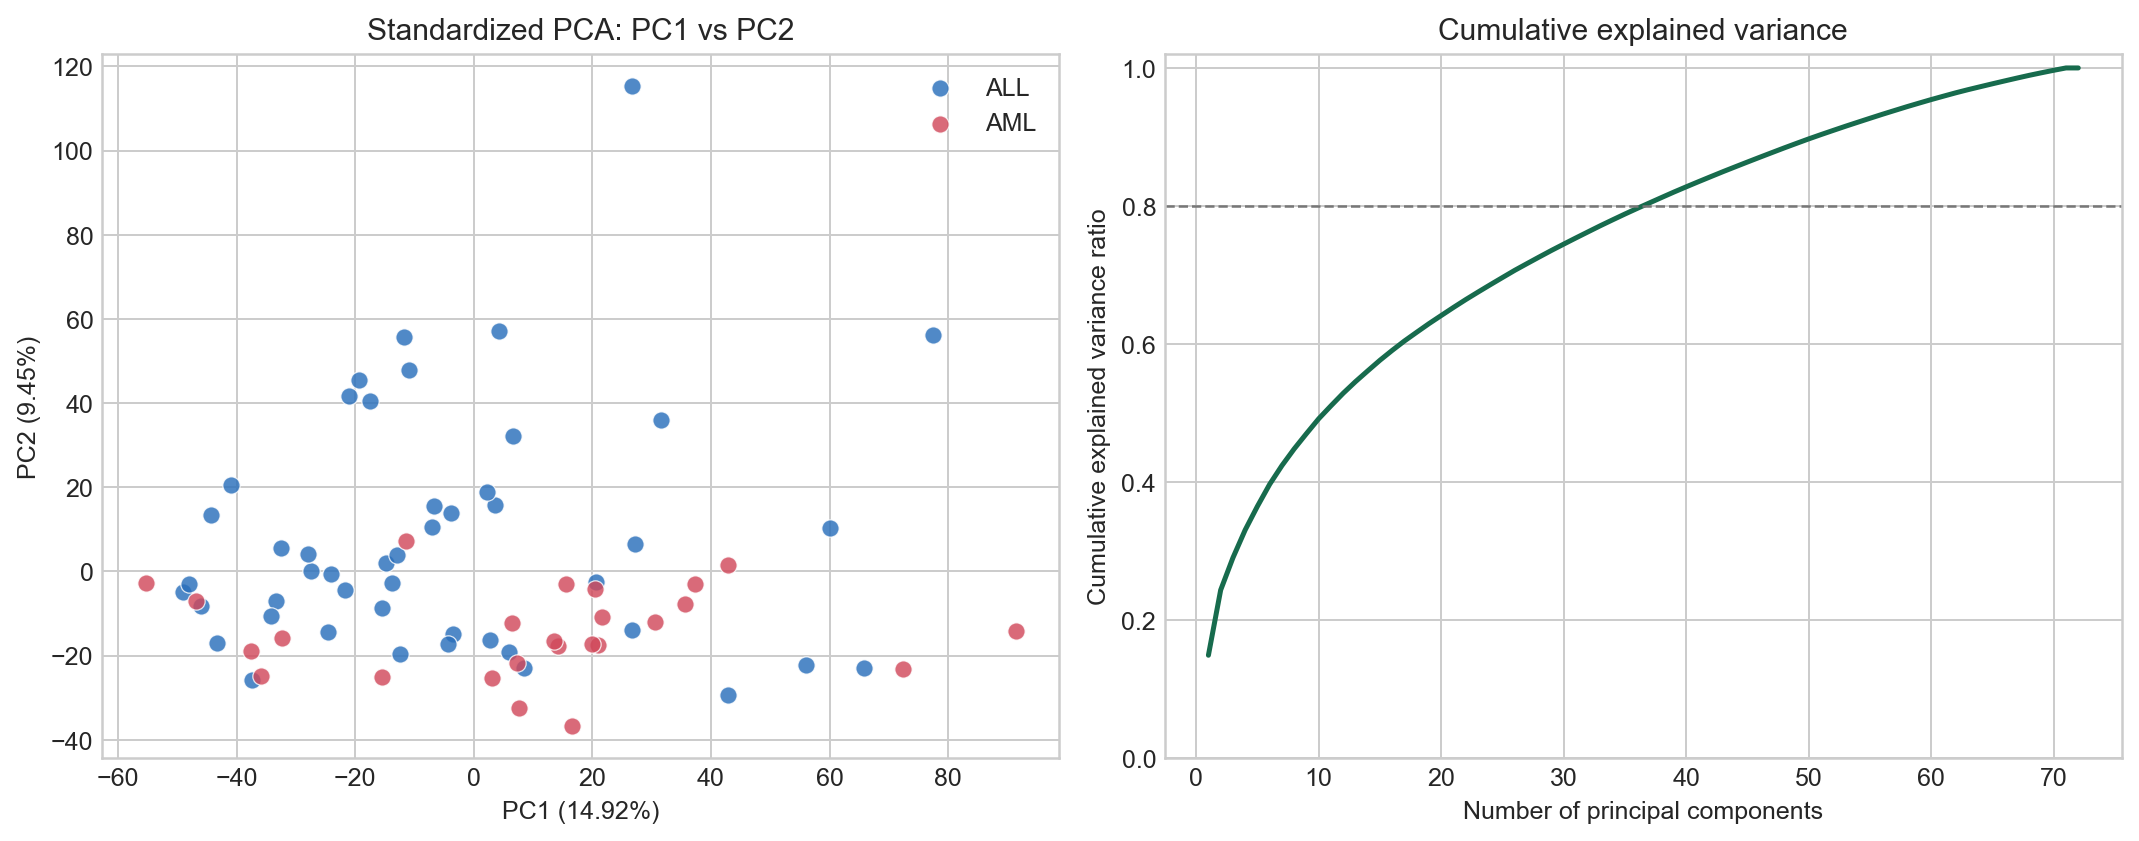

In [3]:
scaler = StandardScaler(with_mean=True, with_std=True)
Xz = scaler.fit_transform(X)
mean_abs_max = np.abs(Xz.mean(axis=0)).max()
std_min = Xz.std(axis=0, ddof=0).min()
std_max = Xz.std(axis=0, ddof=0).max()

pca = PCA(svd_solver="full")
scores = pca.fit_transform(Xz)
evr = pca.explained_variance_ratio_
loadings = pca.components_.T
top_idx = np.argsort(np.abs(loadings[:, 0]))[-5:][::-1]
top5 = pd.DataFrame({
    "probe": feature_names[top_idx],
    "PC1_loading": loadings[top_idx, 0],
    "abs_loading": np.abs(loadings[top_idx, 0]),
})

print(f"标准化后最大绝对列均值: {mean_abs_max:.3e}")
print(f"标准化后总体列标准差范围(ddof=0): {std_min:.6f} 到 {std_max:.6f}")
print(f"PC1解释率: {evr[0]:.6f} ({evr[0]*100:.3f}%)")
print(f"PC2解释率: {evr[1]:.6f} ({evr[1]*100:.3f}%)")
print(f"PC1+PC2累计解释率: {evr[:2].sum():.6f} ({evr[:2].sum()*100:.3f}%)")
print("前10个主成分累计解释率:", np.round(np.cumsum(evr)[:10], 6).tolist())
print("PC1绝对权重最大的5个探针:\n", top5.to_string(index=False))
print("数值上大于1e-12的主成分个数:", int((pca.explained_variance_ > 1e-12).sum()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
colors = {"ALL": "#2A6FBB", "AML": "#D1495B"}
for label in ["ALL", "AML"]:
    mask = y == label
    axes[0].scatter(scores[mask, 0], scores[mask, 1], s=48, alpha=0.82,
                    label=label, color=colors[label], edgecolor="white", linewidth=0.5)
axes[0].set_xlabel(f"PC1 ({evr[0]*100:.2f}%)")
axes[0].set_ylabel(f"PC2 ({evr[1]*100:.2f}%)")
axes[0].set_title("Standardized PCA: PC1 vs PC2")
axes[0].legend()
axes[1].plot(np.arange(1, len(evr) + 1), np.cumsum(evr), color="#176B4D", linewidth=2)
axes[1].axhline(0.8, color="#777777", linestyle="--", linewidth=1)
axes[1].set_xlabel("Number of principal components")
axes[1].set_ylabel("Cumulative explained variance ratio")
axes[1].set_ylim(0, 1.02)
axes[1].set_title("Cumulative explained variance")
fig.tight_layout()
pca_fig = OUT / "pca-results.png"
fig.savefig(pca_fig, dpi=180, bbox_inches="tight")
plt.close(fig)

PC1 最大化的是标准化数据投影到一条线后的样本方差。它是 7,129 个探针的加权组合，不是某一个基因，也不是专门寻找最能区分 ALL/AML 的监督方向。主成分的所有权重和得分同时乘以 -1，只会把坐标轴翻转，不改变解释率、样本距离或结论。中心化后 72 行之和为零，矩阵秩至多为 71，因此最多只有 71 个非零主成分。

仅中心化PCA PC1解释率: 0.174278 (17.428%)
仅中心化PCA PC2解释率: 0.103386 (10.339%)
仅中心化PCA PC1+PC2: 0.277664 (27.766%)
仅中心化PCA的PC1绝对权重前5:
              probe  PC1_loading  abs_loading
       M25079_s_at     0.352388     0.352388
        hum_alu_at     0.313552     0.313552
HG1428-HT1428_s_at     0.234867     0.234867
         L06499_at     0.210453     0.210453
       J04617_s_at     0.196253     0.196253


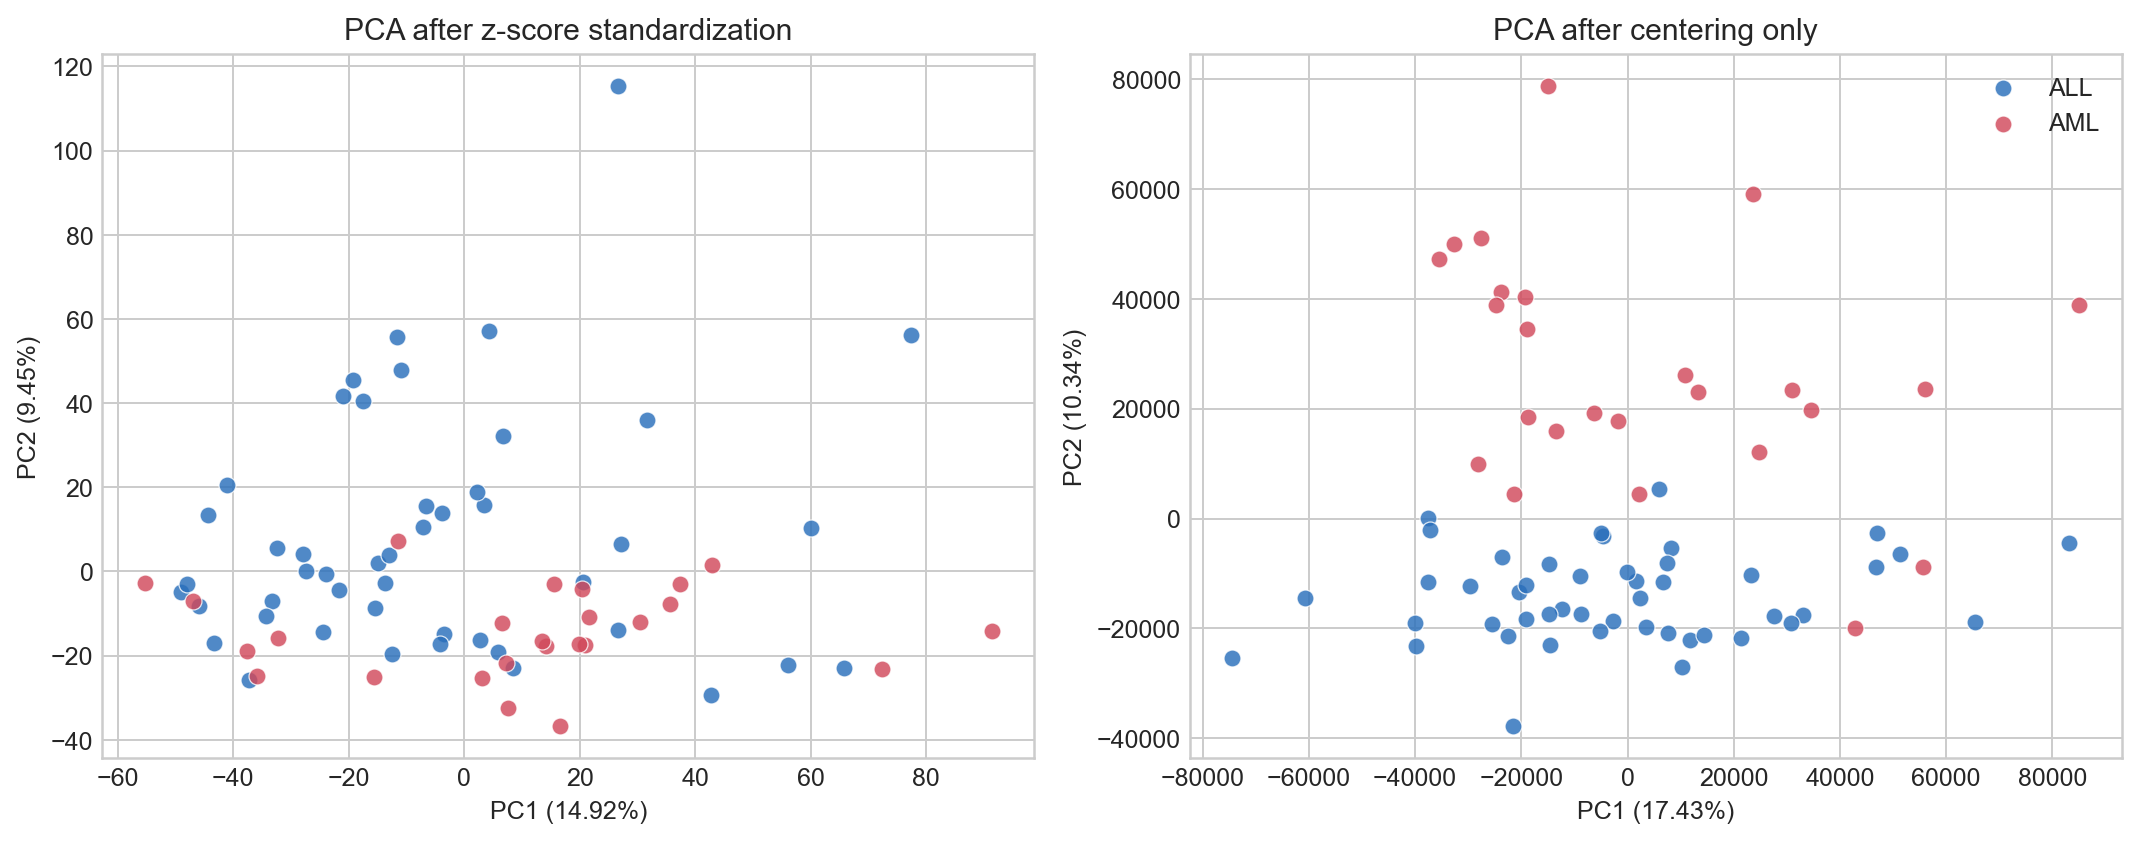

In [4]:
raw_pca = PCA(svd_solver="full")
raw_scores = raw_pca.fit_transform(X)
raw_evr = raw_pca.explained_variance_ratio_
raw_loadings = raw_pca.components_.T
raw_top_idx = np.argsort(np.abs(raw_loadings[:, 0]))[-5:][::-1]
raw_top5 = pd.DataFrame({
    "probe": feature_names[raw_top_idx],
    "PC1_loading": raw_loadings[raw_top_idx, 0],
    "abs_loading": np.abs(raw_loadings[raw_top_idx, 0]),
})

print(f"仅中心化PCA PC1解释率: {raw_evr[0]:.6f} ({raw_evr[0]*100:.3f}%)")
print(f"仅中心化PCA PC2解释率: {raw_evr[1]:.6f} ({raw_evr[1]*100:.3f}%)")
print(f"仅中心化PCA PC1+PC2: {raw_evr[:2].sum():.6f} ({raw_evr[:2].sum()*100:.3f}%)")
print("仅中心化PCA的PC1绝对权重前5:\n", raw_top5.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for label in ["ALL", "AML"]:
    mask = y == label
    axes[0].scatter(scores[mask, 0], scores[mask, 1], s=46, alpha=0.82,
                    label=label, color=colors[label], edgecolor="white", linewidth=0.5)
    axes[1].scatter(raw_scores[mask, 0], raw_scores[mask, 1], s=46, alpha=0.82,
                    label=label, color=colors[label], edgecolor="white", linewidth=0.5)
axes[0].set_title("PCA after z-score standardization")
axes[0].set_xlabel(f"PC1 ({evr[0]*100:.2f}%)")
axes[0].set_ylabel(f"PC2 ({evr[1]*100:.2f}%)")
axes[1].set_title("PCA after centering only")
axes[1].set_xlabel(f"PC1 ({raw_evr[0]*100:.2f}%)")
axes[1].set_ylabel(f"PC2 ({raw_evr[1]*100:.2f}%)")
axes[1].legend()
fig.tight_layout()
scale_fig = OUT / "pca-scale-comparison.png"
fig.savefig(scale_fig, dpi=180, bbox_inches="tight")
plt.close(fig)

标准化防止原始量纲或大方差探针仅凭数值尺度支配主成分，使不同探针更可比较；代价是低变异但噪声较大的探针也可能被放大。这里的列标准化不是微阵列实验在上游做的背景校正和归一化，不能互相替代。

## 任务 3：UMAP 上的簇可以相信到什么程度？

基线固定 `n_neighbors=15`、`min_dist=0.1`、欧氏距离、`random_state=42`、`n_jobs=1`。三个对照每次只改变一个因素：邻居数改为 5、`min_dist` 改为 0.5、随机种子改为 7。标签不参与拟合。

PCA 是线性投影，按顺序最大化方差，坐标轴有明确的方差方向并能报告解释率。UMAP 是非线性邻域嵌入，主要保留局部邻接；坐标轴本身没有生物学含义，不能报告 explained variance。UMAP 的全局距离、方向、面积和岛屿间空隙不应按原空间的定量距离解释。两者用于预测时都必须在训练折内拟合。

UMAP设置对照指标:
                  setting  trustworthiness_k5  baseline_5NN_overlap  pairwise_distance_spearman  procrustes_disparity
baseline_n15_d0.1_seed42            0.819054              1.000000                    1.000000              0.000000
           n_neighbors_5            0.800000              0.541667                    0.755190              0.250846
            min_dist_0.5            0.801997              0.583333                    0.881090              0.173256
                  seed_7            0.829167              0.636111                    0.927948              0.076625

四种设置中共同5近邻最多的样本:
 sample_id  common_5NN_count             common_neighbors
     G004                 5 G001, G007, G008, G027, G049
     G008                 4       G004, G007, G027, G049
     G009                 4       G002, G003, G011, G014
     G027                 4       G004, G007, G008, G049
     G049                 4       G004, G007, G008, G027
     G001                 3             G

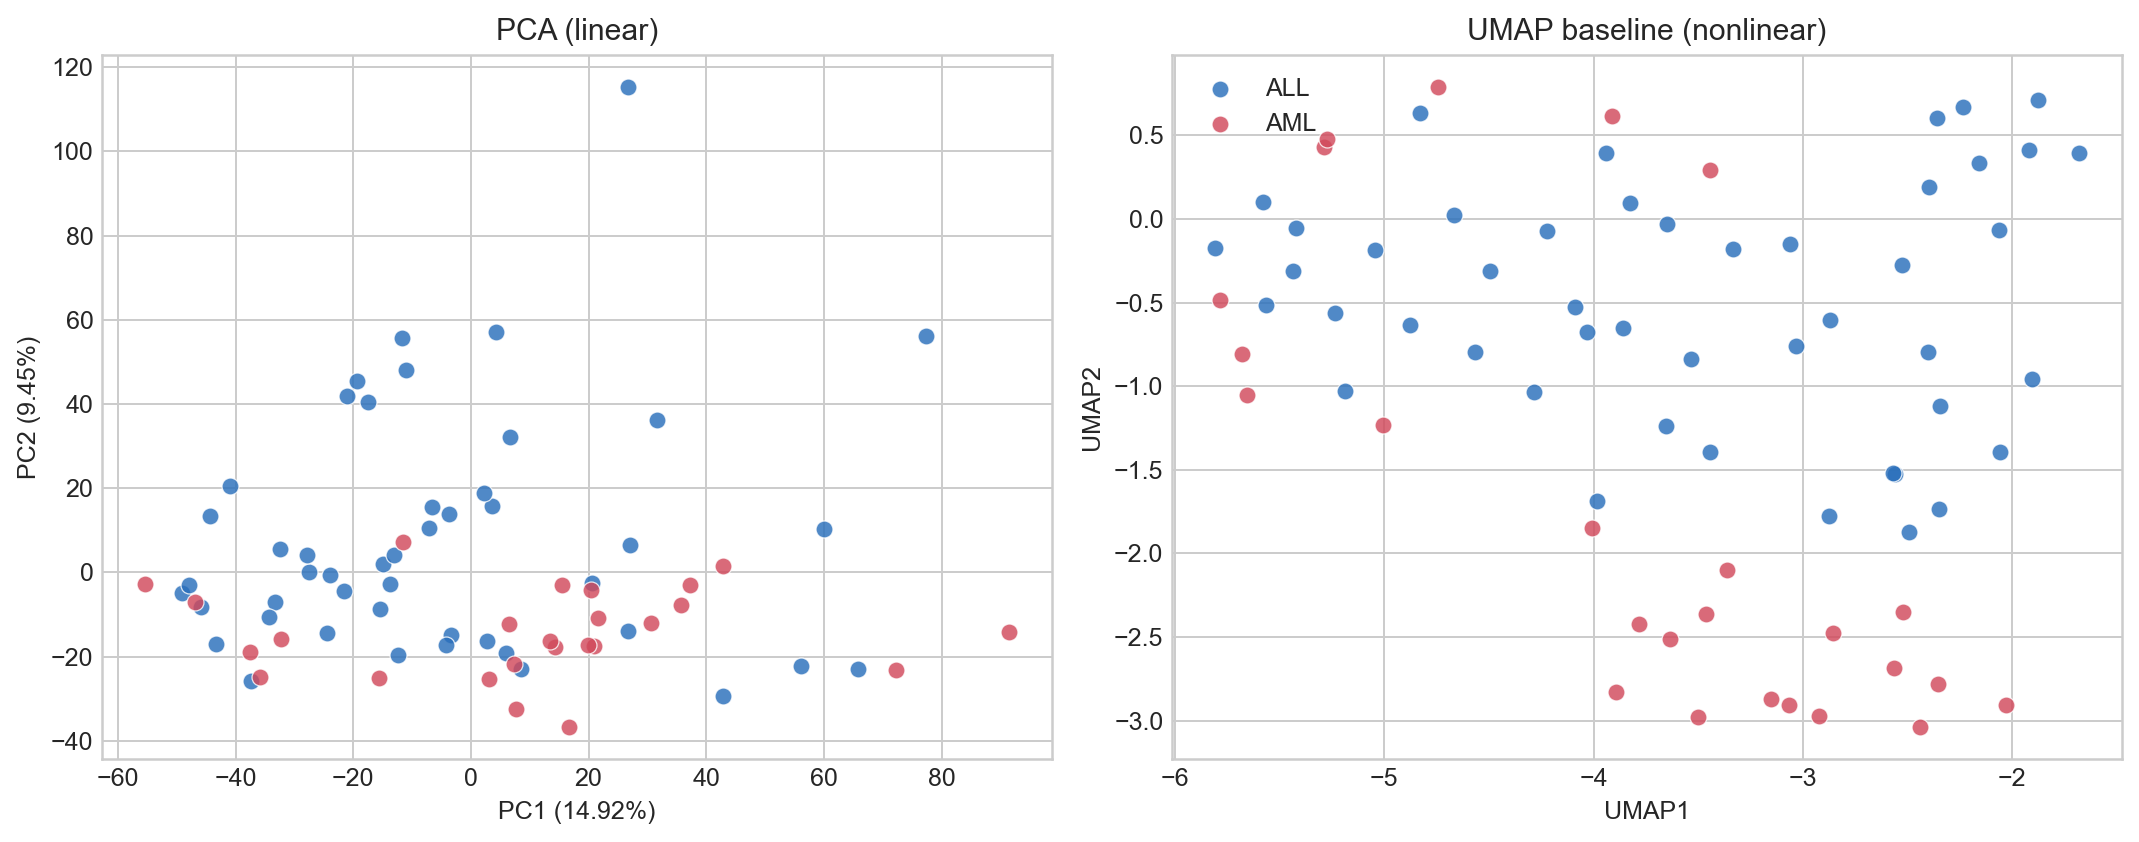

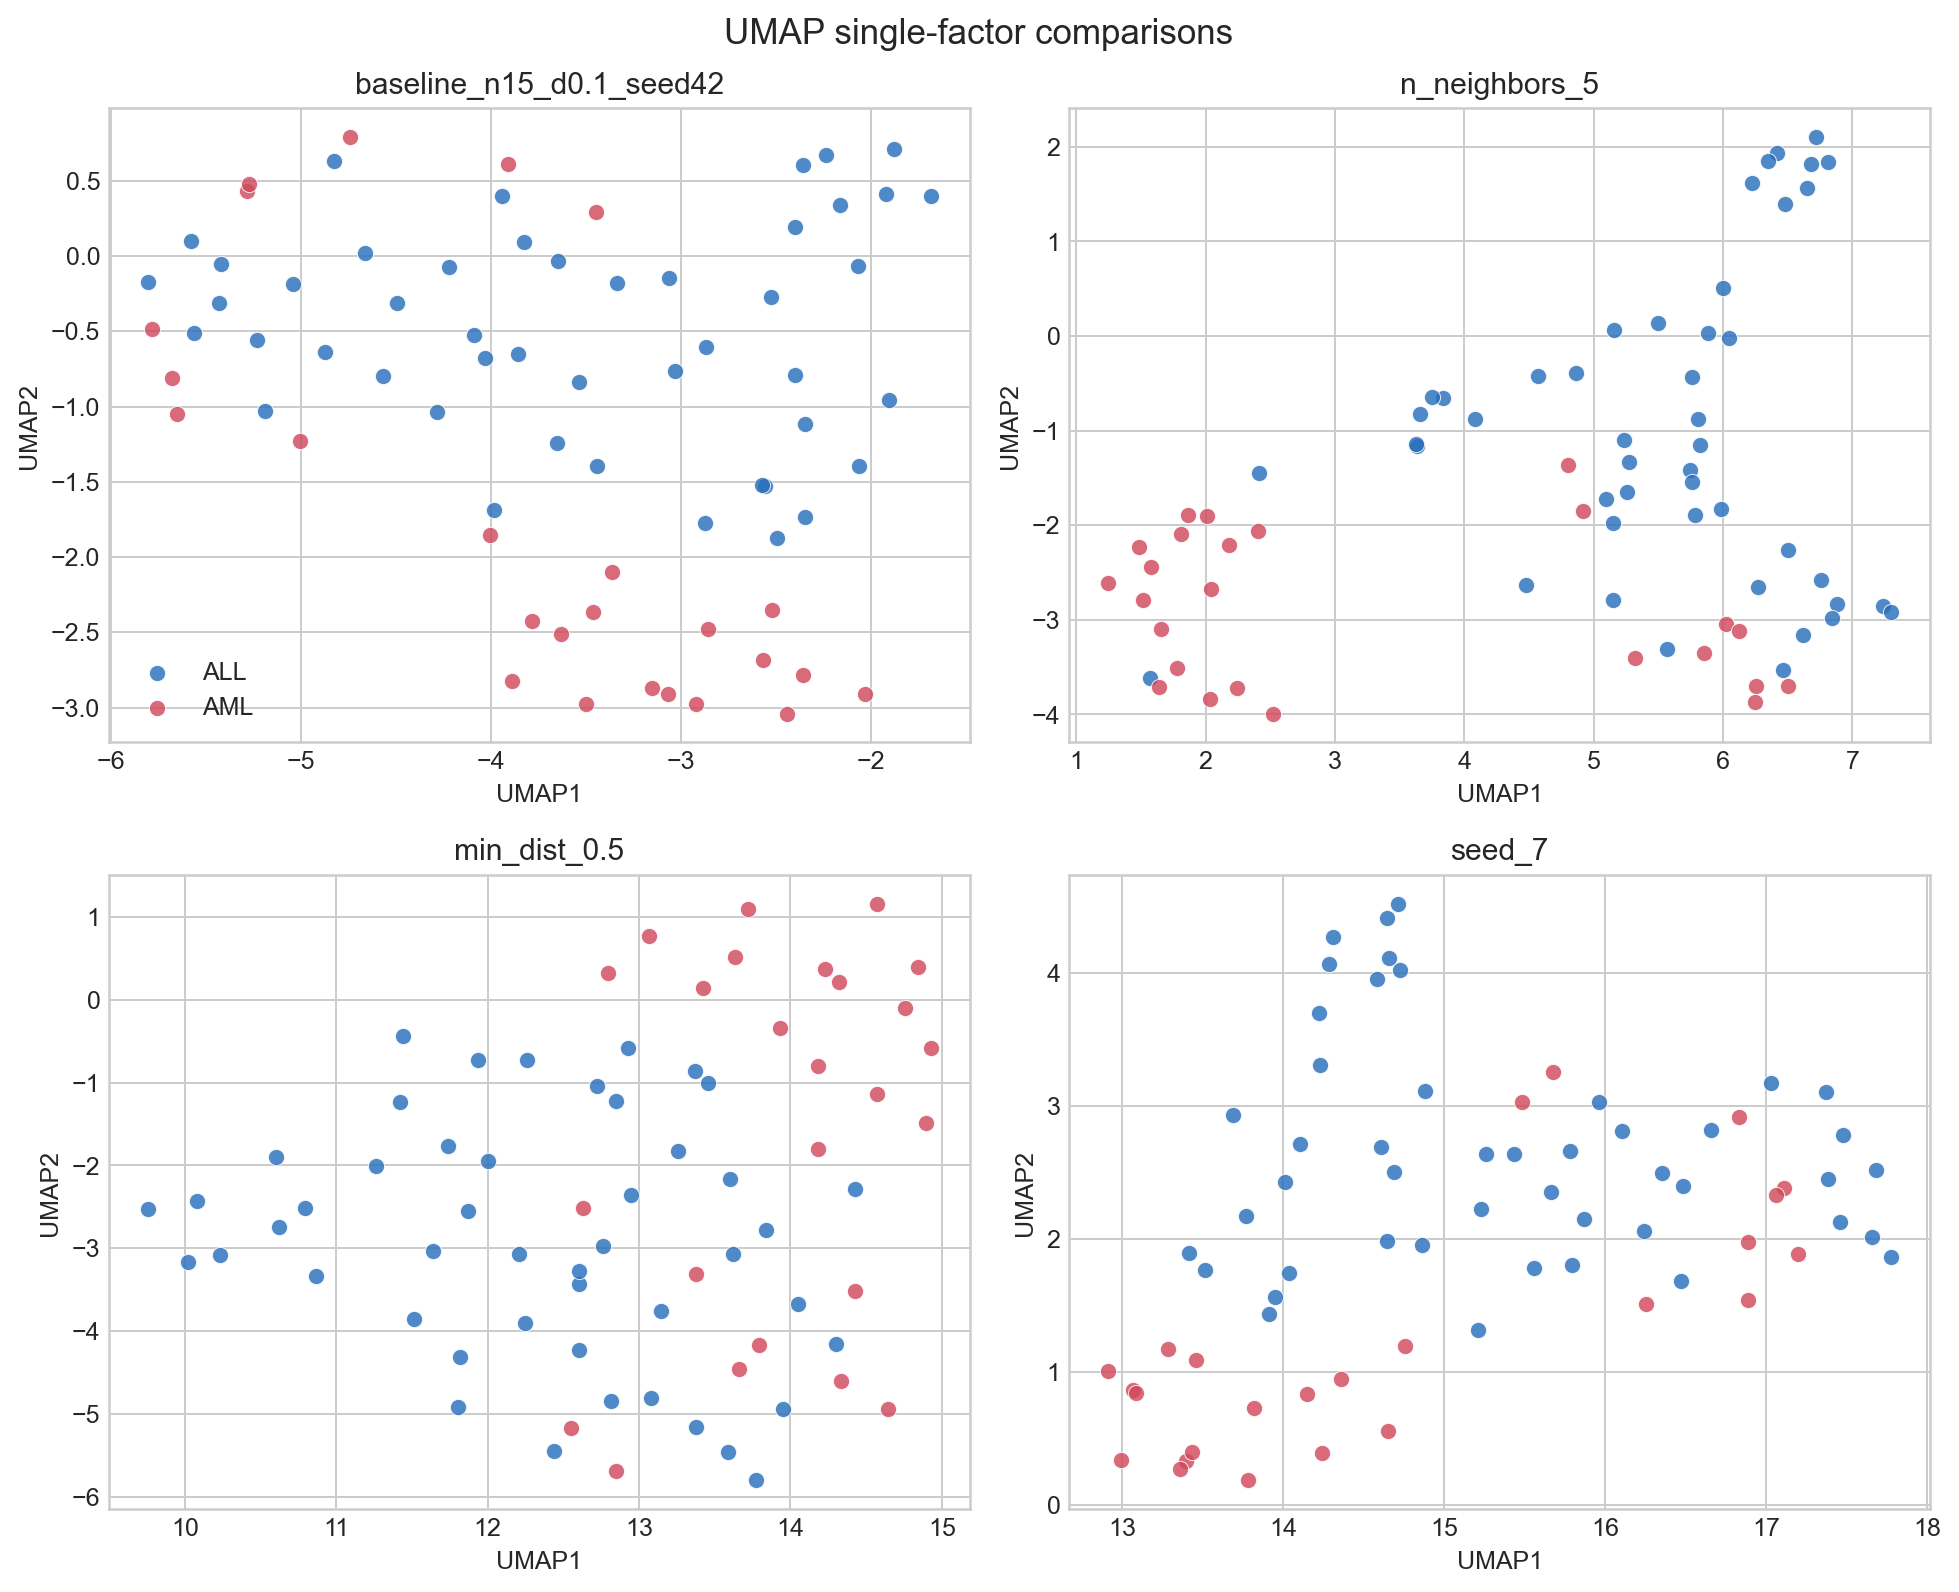

In [5]:
configs = OrderedDict([
    ("baseline_n15_d0.1_seed42", dict(n_neighbors=15, min_dist=0.1, random_state=42)),
    ("n_neighbors_5", dict(n_neighbors=5, min_dist=0.1, random_state=42)),
    ("min_dist_0.5", dict(n_neighbors=15, min_dist=0.5, random_state=42)),
    ("seed_7", dict(n_neighbors=15, min_dist=0.1, random_state=7)),
])

umap_coords = {}
for label, params in configs.items():
    model = umap.UMAP(
        n_components=2,
        metric="euclidean",
        n_jobs=1,
        **params,
    )
    umap_coords[label] = model.fit_transform(Xz)

def neighbor_sets(points, k=5):
    indices = NearestNeighbors(n_neighbors=k).fit(points).kneighbors(return_distance=False)
    return [set(row.tolist()) for row in indices]

base_label = next(iter(configs))
base_points = umap_coords[base_label]
base_neighbors = neighbor_sets(base_points)
comparison_rows = []
for label, points in umap_coords.items():
    current_neighbors = neighbor_sets(points)
    overlap = np.mean([
        len(base_neighbors[i] & current_neighbors[i]) / 5
        for i in range(len(df))
    ])
    rho = spearmanr(pdist(base_points), pdist(points)).statistic
    disparity = 0.0 if label == base_label else procrustes(base_points, points)[2]
    comparison_rows.append({
        "setting": label,
        "trustworthiness_k5": trustworthiness(Xz, points, n_neighbors=5),
        "baseline_5NN_overlap": overlap,
        "pairwise_distance_spearman": rho,
        "procrustes_disparity": disparity,
    })
umap_compare = pd.DataFrame(comparison_rows)

all_neighbor_sets = [neighbor_sets(points) for points in umap_coords.values()]
stable_rows = []
for i, sample_id in enumerate(df["sample_id"]):
    common = set.intersection(*(sets[i] for sets in all_neighbor_sets))
    stable_rows.append({
        "sample_id": sample_id,
        "common_5NN_count": len(common),
        "common_neighbors": ", ".join(df.iloc[sorted(common)]["sample_id"].tolist()),
    })
stable_neighbors = pd.DataFrame(stable_rows).sort_values(
    ["common_5NN_count", "sample_id"], ascending=[False, True]
)

coords = df[["sample_id", "diagnosis"]].copy()
coords["PC1"] = scores[:, 0]
coords["PC2"] = scores[:, 1]
for label, points in umap_coords.items():
    coords[f"{label}_x"] = points[:, 0]
    coords[f"{label}_y"] = points[:, 1]
coords.to_csv(OUT / "sample-coordinate-map.csv", index=False)

print("UMAP设置对照指标:\n", umap_compare.round(6).to_string(index=False))
print("\n四种设置中共同5近邻最多的样本:\n",
      stable_neighbors.head(10).to_string(index=False))
print("\n每个样本在四种设置中共同5近邻个数的均值:",
      round(stable_neighbors["common_5NN_count"].mean(), 6))

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (label, points) in zip(axes.ravel(), umap_coords.items()):
    for diagnosis in ["ALL", "AML"]:
        mask = y == diagnosis
        ax.scatter(points[mask, 0], points[mask, 1], s=42, alpha=0.82,
                   label=diagnosis, color=colors[diagnosis], edgecolor="white", linewidth=0.4)
    ax.set_title(label)
    ax.set_xlabel("UMAP1")
    ax.set_ylabel("UMAP2")
axes[0, 0].legend()
fig.suptitle("UMAP single-factor comparisons", fontsize=14)
fig.tight_layout()
umap_fig = OUT / "umap-parameter-comparison.png"
fig.savefig(umap_fig, dpi=180, bbox_inches="tight")
plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for diagnosis in ["ALL", "AML"]:
    mask = y == diagnosis
    axes[0].scatter(scores[mask, 0], scores[mask, 1], s=46, alpha=0.82,
                    label=diagnosis, color=colors[diagnosis], edgecolor="white", linewidth=0.5)
    axes[1].scatter(base_points[mask, 0], base_points[mask, 1], s=46, alpha=0.82,
                    label=diagnosis, color=colors[diagnosis], edgecolor="white", linewidth=0.5)
axes[0].set_title("PCA (linear)")
axes[0].set_xlabel(f"PC1 ({evr[0]*100:.2f}%)")
axes[0].set_ylabel(f"PC2 ({evr[1]*100:.2f}%)")
axes[1].set_title("UMAP baseline (nonlinear)")
axes[1].set_xlabel("UMAP1")
axes[1].set_ylabel("UMAP2")
axes[1].legend()
fig.tight_layout()
pca_umap_fig = OUT / "pca-vs-umap.png"
fig.savefig(pca_umap_fig, dpi=180, bbox_inches="tight")
plt.close(fig)

UMAP 适合展示单细胞或复杂表型，是因为它能把高维、可能非线性的局部邻域压到二维，便于发现候选连续变化、离群点和局部群体。但图上分离只是探索性模式：不能单独证明疾病机制、真实亚型数量或新患者预测性能。本数据没有批次、中心等字段，所以也不能宣称已经排除批次影响。参数或种子变化后仍重复出现的近邻关系相对更可信；岛屿数量、方向、面积和岛屿间距离出现变化时，不应把单张最清楚的图当成唯一证据。

## 可选验证：训练折内的预测流程

以下对照只使用原始 38 个训练样本，采用 `StratifiedKFold(3, shuffle=True, random_state=42)`。标准化、PCA 和 1 近邻分类器都放进 Pipeline，因此每折验证样本不会参与拟合。另 34 个原始测试样本没有被用于调参或评分。

In [6]:
train_mask = df["original_split"].eq("train").to_numpy()
X_train = X[train_mask]
y_train = y[train_mask]
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

pipelines = {
    "StandardScaler -> 1NN": Pipeline([
        ("scale", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=1)),
    ]),
    "StandardScaler -> PCA(10) -> 1NN": Pipeline([
        ("scale", StandardScaler()),
        ("pca", PCA(n_components=10, svd_solver="full")),
        ("knn", KNeighborsClassifier(n_neighbors=1)),
    ]),
}
cv_rows = []
for method, pipeline in pipelines.items():
    fold_scores = cross_val_score(
        pipeline, X_train, y_train, cv=cv, scoring="balanced_accuracy"
    )
    cv_rows.append({
        "method": method,
        "fold_1": fold_scores[0],
        "fold_2": fold_scores[1],
        "fold_3": fold_scores[2],
        "mean": fold_scores.mean(),
    })
cv_results = pd.DataFrame(cv_rows)
print(cv_results.round(6).to_string(index=False))
print("说明: 仅使用原始38个train样本；三个拟合步骤均在每个训练折内完成。")

D:\Python314\Lib\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
found 0 physical cores < 1
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "D:\Python314\Lib\site-packages\joblib\externals\loky\backend\context.py", line 255, in _count_physical_cores
    raise ValueError(f"found {cpu_count_physical} physical cores < 1")
                          method   fold_1   fold_2   fold_3     mean
           StandardScaler -> 1NN 0.819444 0.875000 0.833333 0.842593
StandardScaler -> PCA(10) -> 1NN 0.694444 0.763889 0.833333 0.763889
说明: 仅使用原始38个train样本；三个拟合步骤均在每个训练折内完成。


## 样本与坐标对应表

下表保留每个样本在 PCA 和四种 UMAP 设置中的坐标，便于跨图追踪同一个样本。

In [7]:
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 20)
print(coords.round(4).to_string(index=False))

sample_id diagnosis      PC1      PC2  baseline_n15_d0.1_seed42_x  baseline_n15_d0.1_seed42_y  n_neighbors_5_x  n_neighbors_5_y  min_dist_0.5_x  min_dist_0.5_y  seed_7_x  seed_7_y
     G001       ALL  27.1052   6.4485                     -2.0609                     -1.3922           4.0849          -0.8800         12.2605         -0.7258 13.770300    2.1735
     G002       ALL   3.5074  15.8458                     -2.8693                     -0.6019           6.0419          -0.0183         11.7383         -1.7696 14.605900    2.6873
     G003       ALL  60.0064  10.3923                     -2.3470                     -1.1186           5.1583           0.0648         11.9368         -0.7238 14.010200    2.4270
     G004       ALL  20.6404  -2.6234                     -2.3485                     -1.7328           3.8330          -0.6580         12.9297         -0.5793 14.035600    1.7422
     G005       ALL -21.0120  41.7942                     -2.4000                      0.1907       

## 任务 4：主张—证据—推理—边界

1. **主张：**我不同意“二维图分得开，就证明发现了疾病机制，并可以预测新患者”。
2. **证据：**标准化 PCA 的 PC1 和 PC2 分别解释 14.922% 和 9.446% 的方差，PC1 最大绝对权重探针为 `X92518_s_at`（带符号权重 0.028786）；UMAP 将邻居数从 15 改成 5 后，与基线的平均 5 近邻重合率为 0.542，改种子为 7 时为 0.636。
3. **推理：**PCA 和 UMAP 都把高维数据压到二维，分离表示当前样本在特定预处理和参数下存在可见结构，但压缩会丢失信息，UMAP 图形还会随参数与随机性变化，因此二维分离不等于因果机制或预测泛化。
4. **边界：**要把探索性图形升级为生物医学结论，需要在带批次/中心信息的独立患者队列中预先固定流程并复现模式，同时结合探针注释、通路或功能实验；预测能力则另需严格嵌套验证和未参与开发的外部测试集。

### 三道作业

1. **PCA 第一主成分代表什么？**PC1 是所有标准化探针的线性加权组合，使 72 个样本投影后的方差最大。本次 PC1 解释 14.922% 的总方差，其中绝对权重最大的 `X92518_s_at` 权重为 0.028786。这说明该探针对 PC1 方向贡献较大，不代表它单独造成白血病或一定能区分 ALL/AML。
2. **为什么 PCA 前通常考虑标准化？**标准化把不同探针放到可比尺度。本次标准化 PCA 的前两维合计解释 24.368%，仅中心化的原尺度 PCA 前两维合计解释 27.766%，且最高权重探针从 `X92518_s_at` 变为 `M25079_s_at`，说明尺度会明显影响方向。代价是低变异噪声也可能被放大，所以标准化不是永远最优。
3. **UMAP 图能说明什么、不能说明什么？**它能展示当前标准化数据中的候选局部邻域和分离模式。将邻居数改为 5 后，平均 5 近邻重合率为 0.542；改种子为 7 后为 0.636，说明有些近邻稳定、有些会改变。它不能单独证明机制、真实亚型数、批次已排除或新患者预测效果。
